# Climate Data Exploration

This notebook examines the climate inputs for the crop yield project. It will document the CHIRPS and NASA POWER sources, verify their dates and coverage, and prepare state-level climate summaries for comparison with HarvestStat.

The analysis will use downloaded source data only. Any test data, if used, will be clearly identified and excluded from project findings.

## 1. Set paths and inspect the CHIRPS files

Set the project and CHIRPS folder paths, then list the TIFF files that were provided. The notebook will check whether they cover every month from 1999 through 2023.

In [1]:
from pathlib import Path
import re
from collections import Counter

project_root = Path.cwd().parent
chirps_folder = project_root / "data" / "raw" / "chirps"

tif_files = sorted(
    path for path in chirps_folder.iterdir()
    if path.is_file() and path.suffix.lower() in {".tif", ".tiff"}
)

pattern = re.compile(r"chirps-v3\.0\.(\d{4})\.(\d{2})\.tiff?$")
matched = []

for path in tif_files:
    match = pattern.fullmatch(path.name)
    if match:
        matched.append((int(match.group(1)), int(match.group(2)), path))

expected_months = {
    (year, month)
    for year in range(1999, 2024)
    for month in range(1, 13)
}
found_months = [(year, month) for year, month, _ in matched]
counts = Counter(found_months)

print("Project folder:", project_root)
print("CHIRPS folder:", chirps_folder)
print("TIFF files found:", len(tif_files))
print("Files matching the expected filename pattern:", len(matched))
print("Missing months:", sorted(expected_months - set(found_months)))
print("Duplicate months:", sorted(month for month, count in counts.items() if count > 1))
print("First filenames:", [path.name for _, _, path in matched[:3]])
print("Last filenames:", [path.name for _, _, path in matched[-3:]])

Project folder: /Users/davidoffor/Desktop/crop-yield-prediction
CHIRPS folder: /Users/davidoffor/Desktop/crop-yield-prediction/data/raw/chirps
TIFF files found: 300
Files matching the expected filename pattern: 300
Missing months: []
Duplicate months: []
First filenames: ['chirps-v3.0.1999.01.tif', 'chirps-v3.0.1999.02.tif', 'chirps-v3.0.1999.03.tif']
Last filenames: ['chirps-v3.0.2023.10.tif', 'chirps-v3.0.2023.11.tif', 'chirps-v3.0.2023.12.tif']


## 2. Inspect a CHIRPS raster

Inspect the January 1999 GeoTIFF’s coordinate system, spatial extent, dimensions, missing-value marker, and valid pixel values. This confirms how the raster is stored before summarizing it by state.

In [2]:
import rasterio

sample_path = chirps_folder / "chirps-v3.0.1999.01.tif"

with rasterio.open(sample_path) as src:
    rainfall = src.read(1, masked=True)

    print("File:", sample_path.name)
    print("CRS:", src.crs)
    print("Dimensions (rows, columns):", src.height, src.width)
    print("Bounds:", src.bounds)
    print("No-data value:", src.nodata)
    print("Data type:", src.dtypes[0])
    print("Valid pixels:", rainfall.count())
    print("Minimum:", float(rainfall.min()))
    print("Maximum:", float(rainfall.max()))

File: chirps-v3.0.1999.01.tif
CRS: EPSG:4326
Dimensions (rows, columns): 1600 1500
Bounds: BoundingBox(left=-20.0, bottom=-40.000001192092896, right=55.00000111758709, top=40.0)
No-data value: None
Data type: float32
Valid pixels: 2400000
Minimum: -9999.0
Maximum: 1046.801025390625


### Handle CHIRPS missing values

The GeoTIFF does not declare a NoData value, but its raster contains -9999. Treat -9999 as missing, not as rainfall or zero. Count these cells explicitly. Later, check their coverage within Nigeria’s state boundaries, since CHIRPS documents that -9999 can also mark missing or erroneous data in 2023 onward products.

In [3]:
import numpy as np
import rasterio

with rasterio.open(sample_path) as src:
    values = src.read(1)

missing = values == -9999
valid = np.isfinite(values) & ~missing

print("Total raster cells:", values.size)
print("Cells marked -9999:", int(missing.sum()))
print("Valid cells after excluding -9999:", int(valid.sum()))
print("Other negative cells:", int(((values < 0) & ~missing).sum()))
print("Minimum valid rainfall:", float(values[valid].min()))
print("Maximum valid rainfall:", float(values[valid].max()))

Total raster cells: 2400000
Cells marked -9999: 1155006
Valid cells after excluding -9999: 1244994
Other negative cells: 0
Minimum valid rainfall: 0.0
Maximum valid rainfall: 1046.801025390625


## 3. Check CHIRPS coverage within Nigerian states

Overlay the January 1999 raster with the official HarvestStat state boundaries. For each state, count raster cells inside the boundary and report how many are marked -9999. This checks data coverage before calculating state-level rainfall.

In [4]:
import geopandas as gpd
import pandas as pd
import rasterio
from rasterio.mask import mask as raster_mask

boundary_path = project_root / "data" / "raw" / "boundaries" / "hvstat_africa_boundary_v1.2.gpkg"
boundaries = gpd.read_file(boundary_path)
nigeria = boundaries.loc[boundaries["country_code"] == "NG"].copy()

coverage_rows = []

with rasterio.open(sample_path) as src:
    if nigeria.crs != src.crs:
        nigeria = nigeria.to_crs(src.crs)

    for _, state in nigeria.iterrows():
        clipped, _ = raster_mask(
            src,
            [state.geometry],
            crop=True,
            filled=False
        )

        band = clipped[0]
        inside = ~band.mask
        values_in_state = band.data

        total_inside = int(inside.sum())
        missing_inside = int((inside & (values_in_state == -9999)).sum())
        valid_inside = total_inside - missing_inside

        coverage_rows.append({
            "admin_1": state["admin_1"],
            "raster_cells_in_state": total_inside,
            "valid_cells": valid_inside,
            "missing_cells": missing_inside,
            "missing_pct": round(100 * missing_inside / total_inside, 2)
                if total_inside else None,
        })

coverage = pd.DataFrame(coverage_rows).sort_values("missing_pct", ascending=False)
display(coverage)

,admin_1,raster_cells_in_state,valid_cells,missing_cells,missing_pct
0,Abia,153,153,0,0.0
19,Kano,664,664,0,0.0
21,Kebbi,1186,1186,0,0.0
22,Kogi,952,952,0,0.0
23,Kwara,1165,1165,0,0.0
24,Lagos,122,122,0,0.0
25,Nasarawa,861,861,0,0.0
26,Niger,2338,2338,0,0.0
27,Ogun,527,527,0,0.0
28,Ondo,478,478,0,0.0


In [5]:
print(coverage.to_string(index=False))

                  admin_1  raster_cells_in_state  valid_cells  missing_cells  missing_pct
                     Abia                    153          153              0          0.0
                     Kano                    664          664              0          0.0
                    Kebbi                   1186         1186              0          0.0
                     Kogi                    952          952              0          0.0
                    Kwara                   1165         1165              0          0.0
                    Lagos                    122          122              0          0.0
                 Nasarawa                    861          861              0          0.0
                    Niger                   2338         2338              0          0.0
                     Ogun                    527          527              0          0.0
                     Ondo                    478          478              0          0.0
          

In [6]:
print("States checked:", len(coverage))
print("States with missing CHIRPS cells:", int((coverage["missing_cells"] > 0).sum()))
print("Total raster cells inside states:", int(coverage["raster_cells_in_state"].sum()))
print("Total missing cells inside states:", int(coverage["missing_cells"].sum()))

States checked: 37
States with missing CHIRPS cells: 0
Total raster cells inside states: 29931
Total missing cells inside states: 0


## 4. Check missing-cell coverage across all CHIRPS months

For each month, count cells marked -9999 inside each Nigerian state boundary. Summarize how many months have missing cells per state, and the minimum number of valid cells available. Do not replace missing cells with zero.

In [7]:
import geopandas as gpd
import numpy as np
import pandas as pd
import rasterio
from rasterio.features import rasterize
from rasterio.windows import from_bounds

boundary_path = project_root / "data" / "raw" / "boundaries" / "hvstat_africa_boundary_v1.2.gpkg"
boundaries = gpd.read_file(boundary_path)
nigeria = boundaries.loc[boundaries["country_code"] == "NG"].copy().reset_index(drop=True)

if nigeria.crs is None:
    raise ValueError("The boundary file has no coordinate system.")

tif_files = sorted(chirps_folder.glob("*.tif"))

with rasterio.open(tif_files[0]) as src:
    if nigeria.crs != src.crs:
        nigeria = nigeria.to_crs(src.crs)

    window = from_bounds(*nigeria.total_bounds, transform=src.transform)
    window = window.round_offsets().round_lengths()
    grid_transform = src.window_transform(window)
    grid_shape = (int(window.height), int(window.width))

    state_grid = rasterize(
        [(geom, idx + 1) for idx, geom in enumerate(nigeria.geometry)],
        out_shape=grid_shape,
        transform=grid_transform,
        fill=0,
        dtype="int16",
        all_touched=False,
    )

inside = state_grid > 0
cell_counts = np.bincount(
    state_grid[inside],
    minlength=len(nigeria) + 1
)[1:]

coverage_rows = []

for path in tif_files:
    with rasterio.open(path) as src:
        values = src.read(1, window=window)

    if values.shape != state_grid.shape:
        raise ValueError(f"Unexpected raster shape in {path.name}: {values.shape}")

    missing_mask = inside & (values == -9999)
    missing_counts = np.bincount(
        state_grid[missing_mask],
        minlength=len(nigeria) + 1
    )[1:]

    for idx, state in nigeria.iterrows():
        coverage_rows.append({
            "admin_1": state["admin_1"],
            "file": path.name,
            "valid_cells": int(cell_counts[idx] - missing_counts[idx]),
            "missing_cells": int(missing_counts[idx]),
        })

coverage_all = pd.DataFrame(coverage_rows)

summary = (
    coverage_all.groupby("admin_1")
    .agg(
        months_checked=("file", "nunique"),
        months_with_missing=("missing_cells", lambda values: int((values > 0).sum())),
        minimum_valid_cells=("valid_cells", "min"),
        total_missing_cells=("missing_cells", "sum"),
    )
    .reset_index()
)

print("Months with any missing cells:", coverage_all.groupby("file")["missing_cells"].sum().gt(0).sum())
display(summary)
print(summary.to_string(index=False))

Months with any missing cells: 0


,admin_1,months_checked,months_with_missing,minimum_valid_cells,total_missing_cells
0,Abia,300,0,153,0
1,Adamawa,300,0,1132,0
2,Akwa Ibom,300,0,216,0
3,Anambra,300,0,155,0
4,Bauchi,300,0,1626,0
5,Bayelsa,300,0,321,0
6,Benue,300,0,1028,0
7,Borno,300,0,2359,0
8,Cross River,300,0,700,0
9,Delta,300,0,542,0


                  admin_1  months_checked  months_with_missing  minimum_valid_cells  total_missing_cells
                     Abia             300                    0                  153                    0
                  Adamawa             300                    0                 1132                    0
                Akwa Ibom             300                    0                  216                    0
                  Anambra             300                    0                  155                    0
                   Bauchi             300                    0                 1626                    0
                  Bayelsa             300                    0                  321                    0
                    Benue             300                    0                 1028                    0
                    Borno             300                    0                 2359                    0
              Cross River             300              

## 5. Calculate monthly rainfall by state

For each month, calculate the area-weighted mean CHIRPS rainfall for each Nigerian state. Use cells whose centers fall within each state boundary, exclude -9999 and other non-finite values, and retain the year and month. Save the resulting state-month table for later climate and crop-data integration.

In [8]:
import numpy as np
import pandas as pd
import rasterio

# Approximate each raster row's cell area using its latitude.
row_latitudes = (
    grid_transform.f
    + (np.arange(grid_shape[0]) + 0.5) * grid_transform.e
)
pixel_weights = np.broadcast_to(
    np.cos(np.deg2rad(row_latitudes))[:, None],
    grid_shape
)

rainfall_rows = []

for path in tif_files:
    with rasterio.open(path) as src:
        values = src.read(1, window=window)

    valid = inside & np.isfinite(values) & (values != -9999)
    state_ids = state_grid[valid]
    valid_values = values[valid]
    weights = pixel_weights[valid]

    weighted_totals = np.bincount(
        state_ids,
        weights=valid_values * weights,
        minlength=len(nigeria) + 1
    )[1:]

    weight_totals = np.bincount(
        state_ids,
        weights=weights,
        minlength=len(nigeria) + 1
    )[1:]

    means = weighted_totals / weight_totals

    match = pattern.fullmatch(path.name)
    year, month = map(int, match.groups())

    for idx, state in nigeria.iterrows():
        rainfall_rows.append({
            "fnid": state["fnid"],
            "admin_1": state["admin_1"],
            "year": year,
            "month": month,
            "chirps_rainfall_mm": means[idx],
        })

chirps_monthly = pd.DataFrame(rainfall_rows)

print("Rows:", len(chirps_monthly))
print("States:", chirps_monthly["admin_1"].nunique())
print("Months:", chirps_monthly[["year", "month"]].drop_duplicates().shape[0])
print("Missing rainfall values:", chirps_monthly["chirps_rainfall_mm"].isna().sum())
print(
    "Duplicate state-month rows:",
    chirps_monthly.duplicated(["fnid", "year", "month"]).sum()
)
print("Rainfall range (mm/month):")
print(chirps_monthly["chirps_rainfall_mm"].agg(["min", "median", "max"]))
print(chirps_monthly.head(10).to_string(index=False))

output_path = project_root / "data" / "processed" / "climate" / "chirps_nigeria_state_monthly.csv"
chirps_monthly.to_csv(output_path, index=False)
print("Saved:", output_path)

Rows: 11100
States: 37
Months: 300
Missing rainfall values: 0
Duplicate state-month rows: 0
Rainfall range (mm/month):
min         0.000000
median    107.747537
max       894.157954
Name: chirps_rainfall_mm, dtype: float64
      fnid     admin_1  year  month  chirps_rainfall_mm
NG1996A101        Abia  1999      1           67.256815
NG1996A102     Adamawa  1999      1            0.099843
NG1996A103   Akwa Ibom  1999      1           85.400339
NG1996A104     Anambra  1999      1           45.390735
NG1996A105      Bauchi  1999      1            0.053726
NG1996A106     Bayelsa  1999      1           79.033528
NG1996A107       Benue  1999      1           18.042375
NG1996A108       Borno  1999      1            0.000240
NG1996A109 Cross River  1999      1           74.729239
NG1996A110       Delta  1999      1           77.797060
Saved: /Users/davidoffor/Desktop/crop-yield-prediction/data/processed/climate/chirps_nigeria_state_monthly.csv


## 6. Test NASA POWER monthly temperature data

Request monthly T2M, T2M_MAX, and T2M_MIN values for a representative point inside Abia State for 1999–2023. Inspect the returned units, date coverage, and missing values before requesting data for other states.

In [9]:
import requests

abia = nigeria.loc[nigeria["admin_1"] == "Abia"].iloc[0]
abia_point = abia.geometry.representative_point()

url = "https://power.larc.nasa.gov/api/temporal/monthly/point"

params = {
    "parameters": "T2M,T2M_MAX,T2M_MIN",
    "community": "AG",
    "longitude": abia_point.x,
    "latitude": abia_point.y,
    "start": 1999,
    "end": 2023,
    "format": "JSON",
}

response = requests.get(url, params=params, timeout=120)
response.raise_for_status()
power_result = response.json()

print("Test state:", abia["admin_1"])
print("Representative point (longitude, latitude):", abia_point.x, abia_point.y)
print("API messages:", power_result.get("messages"))

for parameter, details in power_result.get("parameters", {}).items():
    monthly_values = details.get("data", {})
    print(
        parameter,
        "| units:", details.get("units"),
        "| months returned:", len(monthly_values),
        "| first:", list(monthly_values.items())[:2],
        "| last:", list(monthly_values.items())[-1:] if monthly_values else [],
    )

Test state: Abia
Representative point (longitude, latitude): 7.483744238141911 5.418409500000044
API messages: []
T2M | units: C | months returned: 0 | first: [] | last: []
T2M_MAX | units: C | months returned: 0 | first: [] | last: []
T2M_MIN | units: C | months returned: 0 | first: [] | last: []


In [10]:
parameter_data = power_result.get("properties", {}).get("parameter", {})
parameter_metadata = power_result.get("parameters", {})
fill_value = power_result.get("header", {}).get("fill_value")

print("API fill value:", fill_value)

for parameter, monthly_values in parameter_data.items():
    metadata = parameter_metadata.get(parameter, {})
    print(
        parameter,
        "| units:", metadata.get("units"),
        "| months returned:", len(monthly_values),
        "| first:", list(monthly_values.items())[:2],
        "| last:", list(monthly_values.items())[-1:],
        "| fill-value months:",
        sum(value == fill_value for value in monthly_values.values())
    )

API fill value: -999.0
T2M | units: C | months returned: 325 | first: [('199901', 25.05), ('199902', 26.18)] | last: [('202313', 26.0)] | fill-value months: 0
T2M_MAX | units: C | months returned: 325 | first: [('199901', 31.86), ('199902', 31.97)] | last: [('202313', 33.44)] | fill-value months: 0
T2M_MIN | units: C | months returned: 325 | first: [('199901', 15.84), ('199902', 22.24)] | last: [('202313', 16.61)] | fill-value months: 0


The 325 entries likely comprise 300 calendar months plus 25 annual summaries. The YYYY13 keys (such as 202313) are not calendar months; the endpoint provides both monthly and annual data. We should exclude those annual entries from the monthly table.

In [11]:
for parameter, values in parameter_data.items():
    monthly_keys = [
        key for key in values
        if key[-2:].isdigit() and 1 <= int(key[-2:]) <= 12
    ]
    annual_keys = [key for key in values if key.endswith("13")]

    print(
        parameter,
        "| calendar months:", len(monthly_keys),
        "| annual summaries:", len(annual_keys),
        "| first month:", min(monthly_keys),
        "| last month:", max(monthly_keys),
    )

T2M | calendar months: 300 | annual summaries: 25 | first month: 199901 | last month: 202312
T2M_MAX | calendar months: 300 | annual summaries: 25 | first month: 199901 | last month: 202312
T2M_MIN | calendar months: 300 | annual summaries: 25 | first month: 199901 | last month: 202312


## 7. Retrieve NASA POWER monthly temperatures by state

Request T2M, T2M_MAX, and T2M_MIN for a representative point inside each Nigerian state for 1999–2023. Retain calendar months 01–12 and exclude the annual summaries coded as month 13. Save each original API response in the raw-data folder and combine the monthly values into one processed table.

NASA POWER values are point-based estimates at its source grid resolution; they are not state-wide averages. The representative-point coordinates are retained so this spatial approximation is documented.

In [12]:
import json
import re
import time
import numpy as np
import pandas as pd
import requests

power_raw_folder = project_root / "data" / "raw" / "nasa_power"
power_raw_folder.mkdir(parents=True, exist_ok=True)

power_parameters = ["T2M", "T2M_MAX", "T2M_MIN"]
power_url = "https://power.larc.nasa.gov/api/temporal/monthly/point"

power_rows = []

for _, state in nigeria.iterrows():
    point = state.geometry.representative_point()

    request_params = {
        "parameters": ",".join(power_parameters),
        "community": "AG",
        "longitude": point.x,
        "latitude": point.y,
        "start": 1999,
        "end": 2023,
        "format": "JSON",
    }

    response = requests.get(power_url, params=request_params, timeout=120)
    response.raise_for_status()
    result = response.json()

    if result.get("messages"):
        raise RuntimeError(f"{state['admin_1']}: {result['messages']}")

    safe_name = re.sub(r"[^a-z0-9]+", "_", state["admin_1"].lower()).strip("_")
    raw_path = power_raw_folder / f"nasa_power_monthly_{safe_name}_1999_2023.json"
    with raw_path.open("w") as file:
        json.dump(result, file)

    parameter_data = result.get("properties", {}).get("parameter", {})
    metadata = result.get("parameters", {})
    fill_value = float(result.get("header", {}).get("fill_value", -999.0))

    for parameter in power_parameters:
        if metadata.get(parameter, {}).get("units") != "C":
            raise ValueError(f"Unexpected units for {parameter} in {state['admin_1']}")

    month_keys = sorted(
        key for key in parameter_data["T2M"]
        if len(key) == 6 and key[-2:].isdigit() and 1 <= int(key[-2:]) <= 12
    )

    if len(month_keys) != 300:
        raise ValueError(f"{state['admin_1']}: expected 300 months, got {len(month_keys)}")

    for parameter in power_parameters:
        if set(month_keys) - set(parameter_data[parameter]):
            raise ValueError(f"{state['admin_1']}: missing {parameter} dates")

    for key in month_keys:
        row = {
            "fnid": state["fnid"],
            "admin_1": state["admin_1"],
            "year": int(key[:4]),
            "month": int(key[4:]),
            "power_longitude": point.x,
            "power_latitude": point.y,
        }

        for parameter in power_parameters:
            value = parameter_data[parameter][key]
            row[parameter] = np.nan if float(value) == fill_value else float(value)

        power_rows.append(row)

    time.sleep(0.25)

power_monthly = pd.DataFrame(power_rows)

print("Rows:", len(power_monthly))
print("States:", power_monthly["admin_1"].nunique())
print("Months:", power_monthly[["year", "month"]].drop_duplicates().shape[0])
print(
    "Duplicate state-month rows:",
    power_monthly.duplicated(["fnid", "year", "month"]).sum()
)
print("Missing values by parameter:")
print(power_monthly[power_parameters].isna().sum().to_string())
print(power_monthly.head(10).to_string(index=False))

output_path = project_root / "data" / "processed" / "climate" / "nasa_power_nigeria_state_monthly.csv"
power_monthly.to_csv(output_path, index=False)
print("Saved:", output_path)

Rows: 11100
States: 37
Months: 300
Duplicate state-month rows: 0
Missing values by parameter:
T2M        0
T2M_MAX    0
T2M_MIN    0
      fnid admin_1  year  month  power_longitude  power_latitude   T2M  T2M_MAX  T2M_MIN
NG1996A101    Abia  1999      1         7.483744         5.41841 25.05    31.86    15.84
NG1996A101    Abia  1999      2         7.483744         5.41841 26.18    31.97    22.24
NG1996A101    Abia  1999      3         7.483744         5.41841 26.62    32.25    22.77
NG1996A101    Abia  1999      4         7.483744         5.41841 26.30    31.63    22.39
NG1996A101    Abia  1999      5         7.483744         5.41841 26.15    32.24    22.42
NG1996A101    Abia  1999      6         7.483744         5.41841 25.49    30.73    21.98
NG1996A101    Abia  1999      7         7.483744         5.41841 24.67    29.98    20.46
NG1996A101    Abia  1999      8         7.483744         5.41841 24.85    29.95    21.28
NG1996A101    Abia  1999      9         7.483744         5.41841 2

## 8. Check and combine monthly climate data

Now we want to check that each NASA POWER representative point lies within its state boundary and that monthly mean temperature falls between the reported minimum and maximum, and then join NASA POWER and CHIRPS by FNID, state, year, and month. Keep the two sources’ different spatial methods documented.

In [13]:
from shapely.geometry import Point

# Check temperature ordering.
temperature_violations = (
    (power_monthly["T2M_MIN"] > power_monthly["T2M"])
    | (power_monthly["T2M"] > power_monthly["T2M_MAX"])
)

print("Temperature-ordering violations:", int(temperature_violations.sum()))
print("Temperature ranges (°C):")
print(power_monthly[["T2M_MIN", "T2M", "T2M_MAX"]].agg(["min", "median", "max"]))

# Check that each requested POWER point is inside its corresponding state.
state_geometry = nigeria.set_index("fnid").geometry
point_checks = []

for fnid, state_data in power_monthly.groupby("fnid"):
    row = state_data.iloc[0]
    point = Point(row["power_longitude"], row["power_latitude"])
    point_checks.append(state_geometry.loc[fnid].contains(point))

print("POWER points checked:", len(point_checks))
print("POWER points outside their state:", sum(not result for result in point_checks))

# Join the two climate sources on the state and month identifiers.
join_keys = ["fnid", "admin_1", "year", "month"]

climate_monthly = chirps_monthly.merge(
    power_monthly,
    on=join_keys,
    how="outer",
    validate="one_to_one",
    indicator=True,
)

print("Join results:")
print(climate_monthly["_merge"].value_counts().to_string())
print("Combined rows:", len(climate_monthly))

climate_monthly = climate_monthly.drop(columns="_merge")

output_path = (
    project_root
    / "data"
    / "processed"
    / "climate"
    / "nigeria_state_monthly_climate.csv"
)
climate_monthly.to_csv(output_path, index=False)
print("Saved:", output_path)

Temperature-ordering violations: 0
Temperature ranges (°C):
        T2M_MIN    T2M  T2M_MAX
min        5.52  16.77    27.15
median    20.72  25.77    32.66
max       26.38  35.36    46.08
POWER points checked: 37
POWER points outside their state: 0
Join results:
_merge
both          11100
left_only         0
right_only        0
Combined rows: 11100
Saved: /Users/davidoffor/Desktop/crop-yield-prediction/data/processed/climate/nigeria_state_monthly_climate.csv


## 9. Explore monthly climate patterns across states

For each state, calculate its 25-year average for each calendar month. Summarize the distribution across states using the median and 10th–90th percentile range. Plot rainfall and temperature seasonality. CHIRPS is an area-weighted state estimate; NASA POWER values come from one representative point per state.

 month  chirps_rainfall_mm_median  chirps_rainfall_mm_p10  chirps_rainfall_mm_p90  T2M_median  T2M_p10  T2M_p90  T2M_MAX_median  T2M_MAX_p10  T2M_MAX_p90  T2M_MIN_median  T2M_MIN_p10  T2M_MIN_p90
     1                   6.148879                0.018519               29.315160     24.3212 22.08872 25.43864         34.4816     32.05808     37.33112         14.4248     10.38048     16.35688
     2                  12.387913                0.089657               57.592083     26.3436 25.18056 27.63648         36.4828     32.88400     40.04600         17.1972     13.22032     19.02576
     3                  43.222055                1.211142              126.183605     27.7192 26.58544 30.15144         36.8148     32.56448     41.81344         20.9052     16.87536     22.60280
     4                 109.633709               13.230064              190.043246     27.9044 26.39016 31.86192         36.0828     32.17688     42.82280         22.4048     19.26536     22.86816
     5              

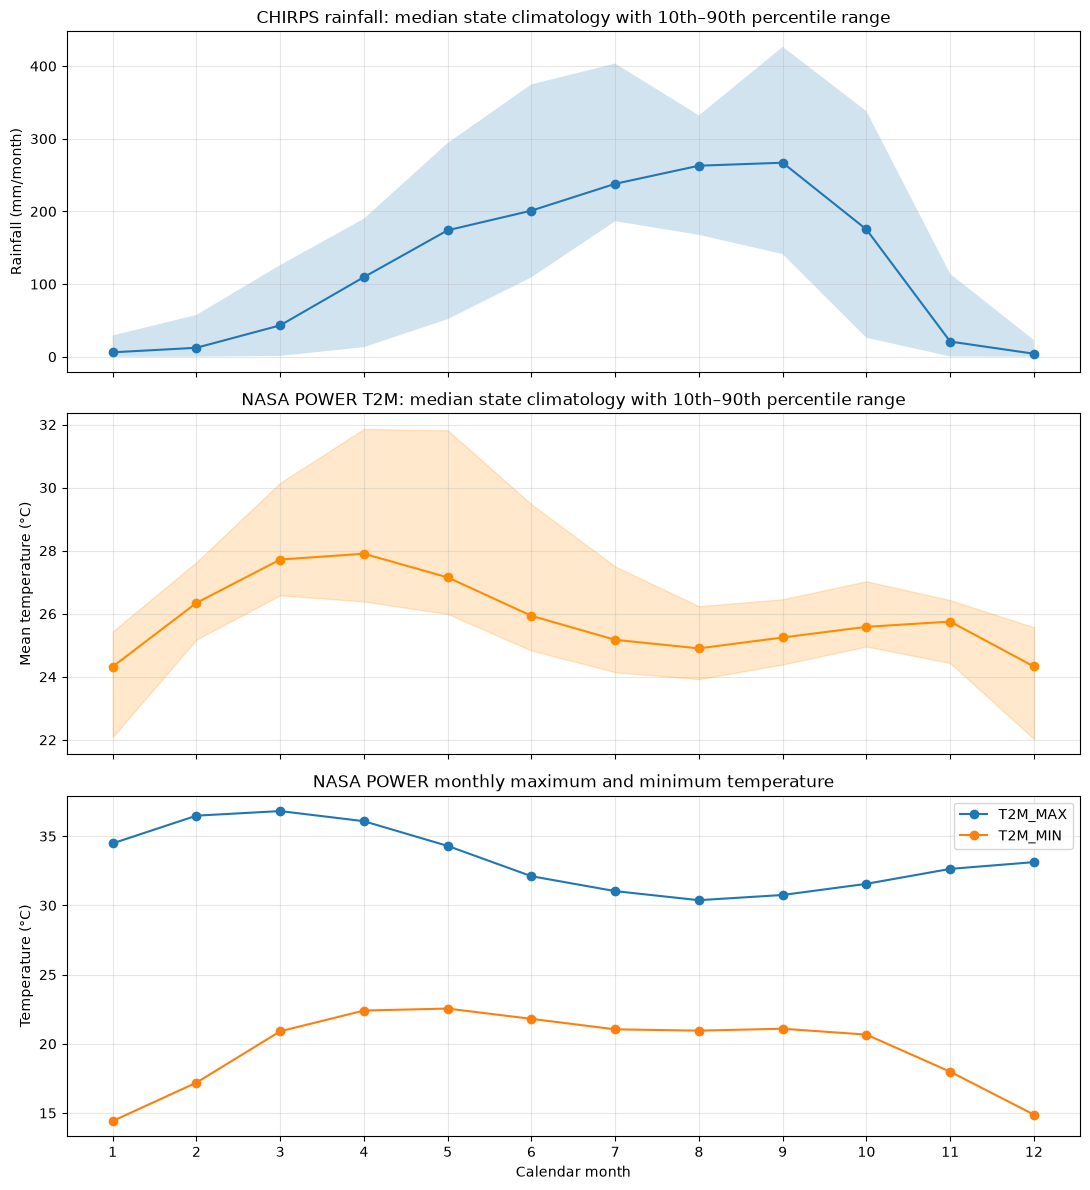

In [14]:
import matplotlib.pyplot as plt
import numpy as np

state_month_climatology = (
    climate_monthly.groupby(["admin_1", "month"], as_index=False)
    .agg(
        chirps_rainfall_mm=("chirps_rainfall_mm", "mean"),
        T2M=("T2M", "mean"),
        T2M_MAX=("T2M_MAX", "mean"),
        T2M_MIN=("T2M_MIN", "mean"),
    )
)

summary_rows = []

for month, group in state_month_climatology.groupby("month"):
    row = {"month": month}

    for variable in ["chirps_rainfall_mm", "T2M", "T2M_MAX", "T2M_MIN"]:
        row[f"{variable}_median"] = group[variable].median()
        row[f"{variable}_p10"] = group[variable].quantile(0.10)
        row[f"{variable}_p90"] = group[variable].quantile(0.90)

    summary_rows.append(row)

monthly_climate_summary = pd.DataFrame(summary_rows).sort_values("month")

print(monthly_climate_summary.to_string(index=False))

months = monthly_climate_summary["month"]

fig, axes = plt.subplots(3, 1, figsize=(11, 12), sharex=True)

axes[0].plot(months, monthly_climate_summary["chirps_rainfall_mm_median"], marker="o")
axes[0].fill_between(
    months,
    monthly_climate_summary["chirps_rainfall_mm_p10"],
    monthly_climate_summary["chirps_rainfall_mm_p90"],
    alpha=0.2,
)
axes[0].set_ylabel("Rainfall (mm/month)")
axes[0].set_title("CHIRPS rainfall: median state climatology with 10th–90th percentile range")
axes[0].grid(True, alpha=0.3)

axes[1].plot(months, monthly_climate_summary["T2M_median"], marker="o", color="darkorange")
axes[1].fill_between(
    months,
    monthly_climate_summary["T2M_p10"],
    monthly_climate_summary["T2M_p90"],
    alpha=0.2,
    color="darkorange",
)
axes[1].set_ylabel("Mean temperature (°C)")
axes[1].set_title("NASA POWER T2M: median state climatology with 10th–90th percentile range")
axes[1].grid(True, alpha=0.3)

axes[2].plot(months, monthly_climate_summary["T2M_MAX_median"], marker="o", label="T2M_MAX")
axes[2].plot(months, monthly_climate_summary["T2M_MIN_median"], marker="o", label="T2M_MIN")
axes[2].set_ylabel("Temperature (°C)")
axes[2].set_xlabel("Calendar month")
axes[2].set_title("NASA POWER monthly maximum and minimum temperature")
axes[2].set_xticks(range(1, 13))
axes[2].grid(True, alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.show()

## 10. Explore annual climate variation by state

Sum monthly CHIRPS rainfall to estimate each state’s annual rainfall total. Calculate annual NASA POWER temperature summaries by weighting each monthly value by the number of days in that month. Compare yearly medians and 10th–90th percentile ranges across states. These are exploratory annual summaries, not yet crop-season features.

 year  states  rainfall_median  rainfall_p10  rainfall_p90  T2M_median   T2M_p10   T2M_p90
 1999      37      1687.564717    821.107424   2763.792725   25.830658 24.865167 27.734367
 2000      37      1425.285238    721.809563   2582.853857   25.398661 24.840339 26.774803
 2001      37      1322.271349    813.084664   2432.356716   25.222082 24.690438 26.870082
 2002      37      1532.695702    803.919214   2673.302716   25.550548 24.916230 27.424088
 2003      37      1480.912068    838.410801   2520.763370   25.796274 25.013529 27.633737
 2004      37      1427.267606    758.046446   2339.240842   25.808880 25.129601 27.889060
 2005      37      1383.783344    774.170540   2544.656400   26.152932 25.158548 28.108055
 2006      37      1533.249575    783.005606   2767.293970   25.940055 25.376690 27.997025
 2007      37      1544.367223    784.783581   2854.810126   25.474932 24.782268 27.161315
 2008      37      1507.842073    719.255125   2703.352768   25.484754 24.626180 26.991568

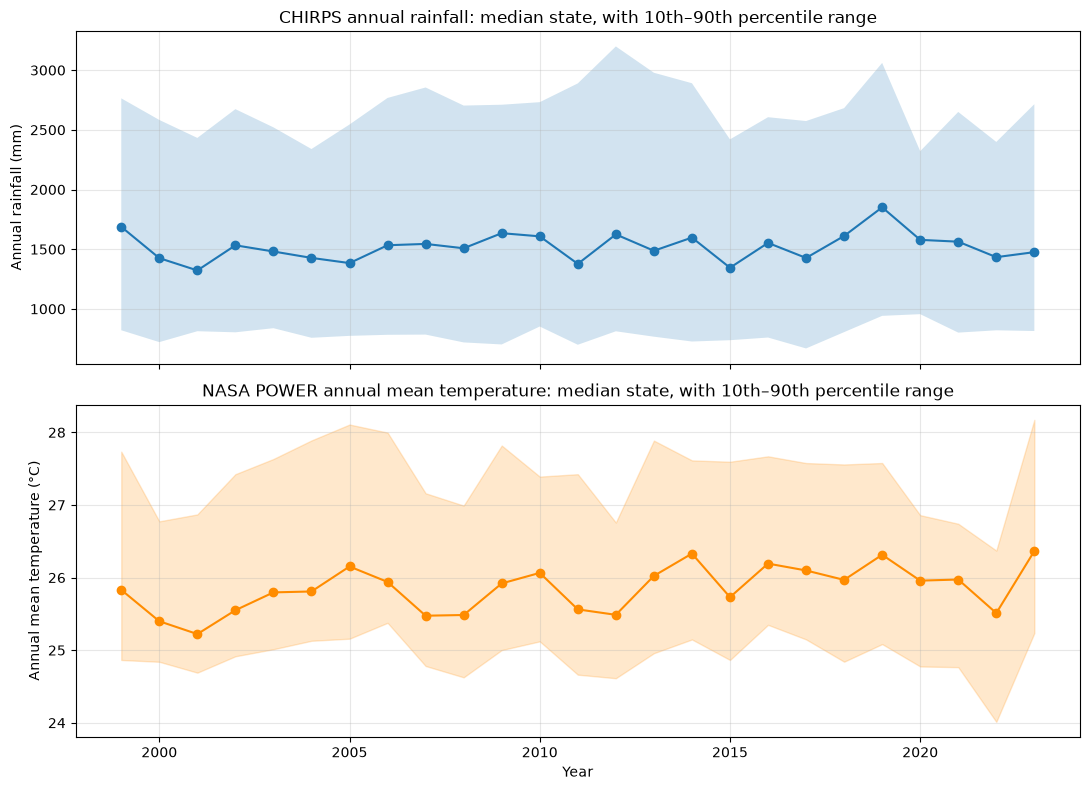

Saved: /Users/davidoffor/Desktop/crop-yield-prediction/data/processed/climate/nigeria_state_annual_climate.csv


In [15]:
annual_input = climate_monthly.copy()

month_dates = pd.to_datetime({
    "year": annual_input["year"],
    "month": annual_input["month"],
    "day": 1,
})
annual_input["days_in_month"] = month_dates.dt.days_in_month

for variable in ["T2M", "T2M_MAX", "T2M_MIN"]:
    annual_input[f"{variable}_weighted"] = (
        annual_input[variable] * annual_input["days_in_month"]
    )

annual_state = (
    annual_input.groupby(["fnid", "admin_1", "year"], as_index=False)
    .agg(
        annual_rainfall_mm=("chirps_rainfall_mm", "sum"),
        days_in_year=("days_in_month", "sum"),
        T2M_weighted_sum=("T2M_weighted", "sum"),
        T2M_MAX_weighted_sum=("T2M_MAX_weighted", "sum"),
        T2M_MIN_weighted_sum=("T2M_MIN_weighted", "sum"),
    )
)

for variable in ["T2M", "T2M_MAX", "T2M_MIN"]:
    annual_state[f"{variable}_annual_mean"] = (
        annual_state[f"{variable}_weighted_sum"] / annual_state["days_in_year"]
    )

annual_summary = (
    annual_state.groupby("year")
    .agg(
        states=("fnid", "nunique"),
        rainfall_median=("annual_rainfall_mm", "median"),
        rainfall_p10=("annual_rainfall_mm", lambda values: values.quantile(0.10)),
        rainfall_p90=("annual_rainfall_mm", lambda values: values.quantile(0.90)),
        T2M_median=("T2M_annual_mean", "median"),
        T2M_p10=("T2M_annual_mean", lambda values: values.quantile(0.10)),
        T2M_p90=("T2M_annual_mean", lambda values: values.quantile(0.90)),
    )
    .reset_index()
)

print(annual_summary.to_string(index=False))

fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)

axes[0].plot(annual_summary["year"], annual_summary["rainfall_median"], marker="o")
axes[0].fill_between(
    annual_summary["year"],
    annual_summary["rainfall_p10"],
    annual_summary["rainfall_p90"],
    alpha=0.2,
)
axes[0].set_ylabel("Annual rainfall (mm)")
axes[0].set_title("CHIRPS annual rainfall: median state, with 10th–90th percentile range")
axes[0].grid(True, alpha=0.3)

axes[1].plot(annual_summary["year"], annual_summary["T2M_median"], marker="o", color="darkorange")
axes[1].fill_between(
    annual_summary["year"],
    annual_summary["T2M_p10"],
    annual_summary["T2M_p90"],
    alpha=0.2,
    color="darkorange",
)
axes[1].set_ylabel("Annual mean temperature (°C)")
axes[1].set_xlabel("Year")
axes[1].set_title("NASA POWER annual mean temperature: median state, with 10th–90th percentile range")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

annual_path = project_root / "data" / "processed" / "climate" / "nigeria_state_annual_climate.csv"
annual_state.to_csv(annual_path, index=False)
print("Saved:", annual_path)

## 11. Map long-term climate averages by state

Map each state’s 1999–2023 mean annual rainfall and mean annual temperature. Use the maps to inspect spatial patterns and check that the extracted climate values are geographically plausible. Rainfall is summarized across each state; NASA POWER temperature is based on a representative point in each state.

States mapped: 37
States with missing map values: 0


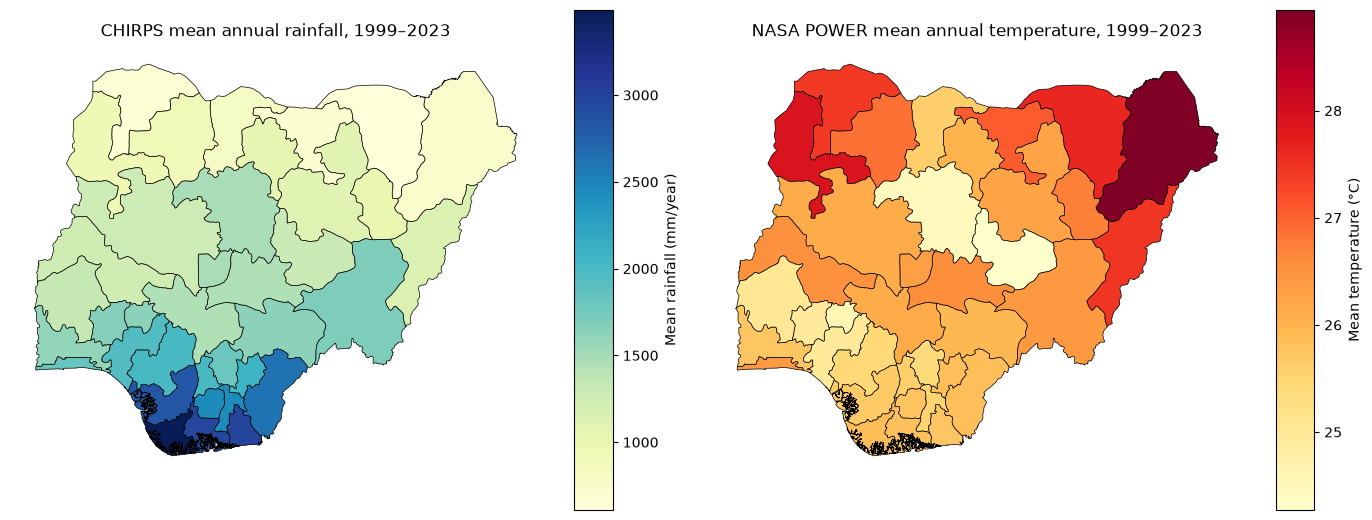

In [16]:
state_climatology = (
    annual_state.groupby(["fnid", "admin_1"], as_index=False)
    .agg(
        mean_annual_rainfall_mm=("annual_rainfall_mm", "mean"),
        mean_annual_T2M_C=("T2M_annual_mean", "mean"),
    )
)

climate_map = nigeria.merge(
    state_climatology,
    on=["fnid", "admin_1"],
    how="left",
    validate="one_to_one",
)

print("States mapped:", len(climate_map))
print(
    "States with missing map values:",
    climate_map[["mean_annual_rainfall_mm", "mean_annual_T2M_C"]].isna().any(axis=1).sum()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 8))

climate_map.plot(
    column="mean_annual_rainfall_mm",
    cmap="YlGnBu",
    linewidth=0.5,
    edgecolor="black",
    legend=True,
    legend_kwds={"label": "Mean rainfall (mm/year)"},
    ax=axes[0],
)
axes[0].set_title("CHIRPS mean annual rainfall, 1999–2023")
axes[0].set_axis_off()

climate_map.plot(
    column="mean_annual_T2M_C",
    cmap="YlOrRd",
    linewidth=0.5,
    edgecolor="black",
    legend=True,
    legend_kwds={"label": "Mean temperature (°C)"},
    ax=axes[1],
)
axes[1].set_title("NASA POWER mean annual temperature, 1999–2023")
axes[1].set_axis_off()

plt.tight_layout()
plt.show()

### Spatial climate pattern

The long-term maps show a broad north–south gradient: rainfall is generally higher in southern states, while temperature is generally higher in northern states. The pattern is geographically plausible, but the maps alone do not independently validate the climate datasets. CHIRPS values are state-area estimates; NASA POWER values represent a point inside each state.

## 12. Inspect crop planting and harvest calendar fields

Review the planting and harvest months for the core crops before creating crop-specific climate features. These fields are used to identify candidate climate windows; do not assume they represent observed field-level dates without further documentation.

In [17]:
harveststat_path = project_root / "data" / "processed" / "harveststat_nigeria.csv"
harveststat = pd.read_csv(harveststat_path)

core_crops = [
    "Maize", "Rice", "Cowpea", "Cassava",
    "Groundnuts (In Shell)", "Yams", "Sorghum", "Millet",
]

crop_calendar = harveststat.loc[
    harveststat["product"].isin(core_crops) & harveststat["yield"].notna()
].copy()

crop_calendar["elapsed_calendar_months"] = (
    (crop_calendar["harvest_year"] * 12 + crop_calendar["harvest_month"])
    - (crop_calendar["planting_year"] * 12 + crop_calendar["planting_month"])
    + 1
)

calendar_profile = (
    crop_calendar.groupby(["product", "season_name"], as_index=False)
    .agg(
        records=("yield", "size"),
        planting_months=(
            "planting_month",
            lambda values: ", ".join(map(str, sorted(values.dropna().astype(int).unique())))
        ),
        harvest_months=(
            "harvest_month",
            lambda values: ", ".join(map(str, sorted(values.dropna().astype(int).unique())))
        ),
        median_calendar_months=("elapsed_calendar_months", "median"),
        shortest_calendar_months=("elapsed_calendar_months", "min"),
        longest_calendar_months=("elapsed_calendar_months", "max"),
    )
)

print(calendar_profile.to_string(index=False))

              product season_name  records planting_months harvest_months  median_calendar_months  shortest_calendar_months  longest_calendar_months
              Cassava      Annual      842               3             10                     8.0                         8                        8
              Cassava         Wet        2               3             10                     8.0                         8                        8
               Cowpea         Wet      838               3             10                     8.0                         8                        8
Groundnuts (In Shell)         Wet      768               3             10                     8.0                         8                        8
                Maize         Wet      919               3             10                     8.0                         8                        8
               Millet         Wet      499               3             10                     8.0         

## 13. Exploratory join of yield and annual climate

Join valid-yield records for the core crops to annual state climate by FNID and harvest year. HarvestStat’s planting and harvest month fields do not represent actual crop phenology, so this annual join is for descriptive exploration only. It does not define crop-season climate exposure and is not ready for use as a forecasting feature.

In [18]:
annual_climate_for_join = annual_state.rename(columns={"year": "harvest_year"})

yield_climate_exploratory = crop_calendar.merge(
    annual_climate_for_join[
        [
            "fnid",
            "admin_1",
            "harvest_year",
            "annual_rainfall_mm",
            "T2M_annual_mean",
            "T2M_MAX_annual_mean",
            "T2M_MIN_annual_mean",
        ]
    ],
    on=["fnid", "admin_1", "harvest_year"],
    how="left",
    validate="many_to_one",
    indicator=True,
)

print("Yield records:", len(crop_calendar))
print("Join results:")
print(yield_climate_exploratory["_merge"].value_counts().to_string())
print(
    "Records missing annual climate:",
    int(yield_climate_exploratory["annual_rainfall_mm"].isna().sum())
)

yield_climate_exploratory = yield_climate_exploratory.drop(columns="_merge")

output_path = (
    project_root
    / "data"
    / "processed"
    / "climate"
    / "nigeria_yield_climate_annual_exploratory.csv"
)
yield_climate_exploratory.to_csv(output_path, index=False)
print("Saved:", output_path)

Yield records: 6004
Join results:
_merge
both          6004
left_only        0
right_only       0
Records missing annual climate: 0


Saved: /Users/davidoffor/Desktop/crop-yield-prediction/data/processed/climate/nigeria_yield_climate_annual_exploratory.csv


## 14. Explore annual climate–yield associations

For each core crop, calculate pooled Spearman correlations between yield and annual rainfall or temperature. Also calculate within-state Pearson correlations after subtracting each state's crop-specific mean from yield and climate values. These are descriptive associations only: the annual climate join is not a crop-season exposure and is not ready for forecasting.

In [19]:
association_rows = []

for crop, group in yield_climate_exploratory.groupby("product"):
    group = group.dropna(
        subset=["yield", "annual_rainfall_mm", "T2M_annual_mean"]
    ).copy()

    group["yield_within_state"] = (
        group["yield"] - group.groupby("fnid")["yield"].transform("mean")
    )
    group["rainfall_within_state"] = (
        group["annual_rainfall_mm"]
        - group.groupby("fnid")["annual_rainfall_mm"].transform("mean")
    )
    group["temperature_within_state"] = (
        group["T2M_annual_mean"]
        - group.groupby("fnid")["T2M_annual_mean"].transform("mean")
    )

    association_rows.append({
        "product": crop,
        "records": len(group),
        "states": group["fnid"].nunique(),
        "qc_flag_0": int((group["qc_flag"] == 0).sum()),
        "qc_flag_1_or_2": int((group["qc_flag"] != 0).sum()),
        "pooled_spearman_yield_rainfall":
            group["yield"].corr(group["annual_rainfall_mm"], method="spearman"),
        "within_state_pearson_yield_rainfall":
            group["yield_within_state"].corr(group["rainfall_within_state"]),
        "pooled_spearman_yield_temperature":
            group["yield"].corr(group["T2M_annual_mean"], method="spearman"),
        "within_state_pearson_yield_temperature":
            group["yield_within_state"].corr(group["temperature_within_state"]),
    })

association_summary = pd.DataFrame(association_rows)
print(association_summary.round(3).to_string(index=False))

              product  records  states  qc_flag_0  qc_flag_1_or_2  pooled_spearman_yield_rainfall  within_state_pearson_yield_rainfall  pooled_spearman_yield_temperature  within_state_pearson_yield_temperature
              Cassava      844      37        740             104                           0.417                                0.038                             -0.448                                  -0.138
               Cowpea      838      37        801              37                           0.091                               -0.012                              0.036                                  -0.001
Groundnuts (In Shell)      768      36        720              48                           0.036                                0.045                              0.096                                   0.035
                Maize      919      37        846              73                           0.123                                0.092                          

### Interpretation of exploratory climate–yield associations

Some pooled correlations appear moderate, particularly for Cassava and Sorghum. These relationships become weak after centering values within states, suggesting that persistent differences between states may explain much of the pooled association. Most within-state correlations are close to zero. This annual comparison does not use actual crop-growth windows, so it is descriptive and should not be interpreted as causal or used directly as a model result. QC-flagged observations were retained in this exploration.